In [1]:
from IPython.core.debugger import set_trace

# Import Generic Classes
import numpy as np
import copy
import pickle
import random

# Import All Custom Classes
import os, sys
sys.path.append(os.path.pardir+"/classes")
sys.path.append(os.path.pardir+"/solvers")
sys.path.append(os.path.pardir+"/one_mobility")
sys.path.append(os.path.curdir + "/sim_store/sim20")
sys.path.append(os.path.pardir+"/crawdad_mobility")


from Server import *
from User import *
from Link import *
from Job import *
from Migration_Plans import *
from Cost_Recordings import *

from sim20_setting import *
from load_crawdad_usr import *
from sub_costs import *


# Import Solver Classes
from Optim_PlanGenerator import *
from SeqGreedy_PlanGenerator import *
from Myopic_PlanGenerator import *
from Naive_PlanGenerator import *
from Cloud_PlanGenerator import *

In [15]:
# Load Crawdad data
# Load All 12 users and trim their info
db_names = []
for i in range(1,13):
    if i != 8 and i != 12:
        db_names += ['LifeMap_GS'+str(i)+'.db']

db = []
for name in db_names:
    print(name)
    name = os.path.pardir+ "/crawdad_mobility/" + name
    df,trace = load_usr(name)
    db += [trace]

LifeMap_GS1.db
LifeMap_GS2.db
LifeMap_GS3.db
LifeMap_GS4.db
LifeMap_GS5.db
LifeMap_GS6.db
LifeMap_GS7.db
LifeMap_GS9.db
LifeMap_GS10.db
LifeMap_GS11.db


In [2]:
# num_user by type
num_users_list = [[1,0,2,0],[2,0,3,0],[5,0,5,0],[7,0,8,0],[10,0,10,0], [15,0,15,0]] #, [20,0,20,0]]
# num_users_list = [[20,0,20,0]]

In [17]:
num_trials = 5
key = "mig_rate"

for k in range(len(num_users_list)):
    Batch_cost_stores = []
    SG_cost_stores = []
    Naive_cost_stores = []
    Myopic_cost_stores = []
    Cloud_cost_stores = []
    
    Batch_mig_stores = []
    SG_mig_stores = []
    Naive_mig_stores = []
    Myopic_mig_stores = []
    Cloud_mig_stores = []

    for i in range(num_trials):

        print("Trial Number:",i, "user_count:", np.sum(num_users_list[k]))

#         print("limited")
#         users, servers, links, jobs, sim_param = simulation_setting(num_users_list[k], db)

        while True:
            try:
                users, servers, links, jobs, sim_param = simulation_setting(num_users_list[k], db)
                Batch_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs, sim_param)
                Batch_plan = Migration_Plans(users,jobs,sim_param)
                Batch_plan.from_seq_greedy(Batch_prob)
                Batch_cost_stores += [Cost_Recordings(Batch_plan)]
                break
            except:
                print("batch_broken, repeating with new users")
                continue
                
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Batch_plan.mig_plan_dict[u][key])
        Batch_mig_stores += [num_mig_cumul]


        # Make SG Prob
        # Set Refresh to false for SG
        refresh_rate = [0,0]
        refresh = False

        jobs2 = copy.deepcopy(jobs)
        for j in range(len(jobs2)):
            jobs2[j].info_from_usr(users[j],refresh_rate,refresh)

        # print("SG prob...")
        SG_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs2, sim_param)
        SG_plan = Migration_Plans(users,jobs2,sim_param)
        SG_plan.from_seq_greedy(SG_prob)
        SG_cost_stores += [Cost_Recordings(SG_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(SG_plan.mig_plan_dict[u][key])
        SG_mig_stores += [num_mig_cumul]

        # Make Cloud Prob
        # print("Cloud prob...")
        Cloud_prob = Cloud_PlanGenerator(users, servers, links, jobs, sim_param)
        Cloud_plan = Migration_Plans(users,jobs,sim_param)
        Cloud_plan.from_seq_greedy(Cloud_prob)
        Cloud_cost_stores += [Cost_Recordings(Cloud_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Cloud_plan.mig_plan_dict[u][key])
        Cloud_mig_stores += [num_mig_cumul]

        # Make Naive Prob
        # print("Naive prob...")
        Naive_prob = Naive_PlanGenerator(users, servers, links, jobs, sim_param)
        Naive_plan = Migration_Plans(users,jobs,sim_param)
        Naive_plan.from_seq_greedy(Naive_prob)
        Naive_cost_stores += [Cost_Recordings(Naive_plan)]
        # print("done!")
        num_mig_cumul = 0
        Naive_mig_stores += [num_mig_cumul]

        # Make Myopic Prob
        # print("Myopic prob...")
        Myopic_prob = Myopic_PlanGenerator(users, servers, links, jobs, sim_param)
        Myopic_plan = Migration_Plans(users,jobs,sim_param)
        Myopic_plan.from_seq_greedy(Myopic_prob)
        Myopic_cost_stores += [Cost_Recordings(Myopic_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Myopic_plan.mig_plan_dict[u][key])
        Myopic_mig_stores += [num_mig_cumul]

        
    cost_stores_dic = {}
    cost_stores_dic["SG"] = SG_cost_stores
    cost_stores_dic["Batch"] = Batch_cost_stores
    cost_stores_dic["Naive"] = Naive_cost_stores
    cost_stores_dic["Myopic"] = Myopic_cost_stores
    cost_stores_dic["Cloud"] = Cloud_cost_stores

    pickle.dump(cost_stores_dic, open(os.path.curdir + "/sim_store/sim20/n2_cost_store_u"+ str(np.sum(num_users_list[k])) +".p", "wb" ) )

    
    mig_stores_dict = {}
    mig_stores_dict['SG'] = SG_mig_stores
    mig_stores_dict['Batch'] = Batch_mig_stores
    mig_stores_dict['Naive'] = Naive_mig_stores
    mig_stores_dict['Myopic'] = Myopic_mig_stores
    mig_stores_dict['Cloud'] = Cloud_mig_stores
    pickle.dump(mig_stores_dict, open(os.path.curdir + "/sim_store/sim20/n2_mig_store_u"+ str(np.sum(num_users_list[k])) +".p", "wb" ) )

    

Trial Number: 0 user_count: 3
Trial Number: 1 user_count: 3
Trial Number: 2 user_count: 3
Trial Number: 3 user_count: 3
Trial Number: 4 user_count: 3
Trial Number: 0 user_count: 5
Trial Number: 1 user_count: 5
Trial Number: 2 user_count: 5
Trial Number: 3 user_count: 5
Trial Number: 4 user_count: 5
Trial Number: 0 user_count: 10
Trial Number: 1 user_count: 10
Trial Number: 2 user_count: 10
Trial Number: 3 user_count: 10
Trial Number: 4 user_count: 10
Trial Number: 0 user_count: 15
Trial Number: 1 user_count: 15
Trial Number: 2 user_count: 15
Trial Number: 3 user_count: 15
Trial Number: 4 user_count: 15
Trial Number: 0 user_count: 20
Trial Number: 1 user_count: 20
Trial Number: 2 user_count: 20
Trial Number: 3 user_count: 20
Trial Number: 4 user_count: 20


### Make figures with cost
1. User Density vs. Total Cost per User
2. User Density vs. Latency Cost per User

In [8]:
latencies_SG = []
latencies_Batch = []
latencies_Myopic = []
latencies_Cloud = []
latencies_Naive = []

total_costs_SG = []
total_costs_Batch = []
total_costs_Myopic = []
total_costs_Cloud = []
total_costs_Naive = []

latencies_SG_var = []
latencies_Batch_var = []
latencies_Myopic_var = []
latencies_Cloud_var = []
latencies_Naive_var = []

total_costs_SG_var = []
total_costs_Batch_var = []
total_costs_Myopic_var = []
total_costs_Cloud_var = []
total_costs_Naive_var = []

for i in range(len(num_users_list)):
    # open a file, where you stored the pickled data
    total_users = np.sum(num_users_list[i])
    name = "/sim_store/sim20/n_cost_store_u"+ str(total_users) +".p"
    file = open(os.path.curdir + name, 'rb')

    # dump information to that file
    data = pickle.load(file)

    SG_cost, Batch_cost, Myopic_cost, Naive_cost, Cloud_cost = obtain_sub_costs(data)
    latencies_SG += [SG_cost[3]/total_users]
    latencies_Batch += [Batch_cost[3]/total_users]
    latencies_Myopic += [Myopic_cost[3]/total_users]
    latencies_Cloud += [Cloud_cost[3]/total_users]
    latencies_Naive += [Naive_cost[3]/total_users]
    
    total_costs_SG += [SG_cost[0]/total_users]
    total_costs_Batch += [Batch_cost[0]/total_users]
    total_costs_Myopic += [Myopic_cost[0]/total_users]
    total_costs_Cloud += [Cloud_cost[0]/total_users]
    total_costs_Naive += [Naive_cost[0]/total_users]
    
    cost_var, lat_var = obtain_sub_vars(data)
    
    latencies_SG_var += [lat_var['SG']/total_users]
    latencies_Batch_var += [lat_var['Batch']/total_users]
    latencies_Myopic_var += [lat_var['Myopic']/total_users]
    latencies_Cloud_var += [lat_var['Cloud']/total_users]
    latencies_Naive_var += [lat_var['Naive']/total_users]

    total_costs_SG_var += [cost_var['SG']/total_users]
    total_costs_Batch_var += [cost_var['Batch']/total_users]
    total_costs_Myopic_var += [cost_var['Myopic']/total_users]
    total_costs_Cloud_var += [cost_var['Cloud']/total_users]
    total_costs_Naive_var += [cost_var['Naive']/total_users]
    
    name2 = "/sim_store/sim20/n_mig_store_u"+ str(total_users) +".p"
    file = open(os.path.curdir + name, 'rb')


In [9]:
print("SG total cost:", total_costs_SG)
print("Bt total cost:", total_costs_Batch)
print("My total cost:", total_costs_Myopic)
print("Cl total cost:", total_costs_Cloud)
print("Na total cost:", total_costs_Naive)

print("SG total var:", total_costs_SG_var)
print("Bt total var:", total_costs_Batch_var)
print("My total var:", total_costs_Myopic_var)
print("Cl total var:", total_costs_Cloud_var)
print("Na total var:", total_costs_Naive_var)


SG total cost: [6.2655069974992985, 5.845650928852852, 6.33863658420651, 6.6893569107726485, 6.953840585966937, 7.104158815369159]
Bt total cost: [4.025546089674626, 4.379549565694485, 4.682264685101946, 5.046242065346983, 5.2903950200155085, 5.446742316188548]
My total cost: [5.890780140975355, 6.0137420393910155, 6.34928491726245, 6.369317286841418, 6.77276324742455, 7.24276000533325]
Cl total cost: [6.2655069974992985, 5.845650928852852, 6.33863658420651, 7.255340801237817, 9.612761179255548, 9.223525689470257]
Na total cost: [9.059309723824777, 9.532933111906479, 8.95305421435152, 9.2181814731175, 8.732382234971135, 8.723523937283092]
SG total var: [1.3179500130589918, 0.27218510110832317, 1.2186647907372694, 0.4512213751008664, 0.48778934970774585, 0.14230700882576555]
Bt total var: [0.479340664213449, 0.554621760581581, 0.7926224820464541, 0.24446561781524231, 0.18571710111283418, 0.3431455018893199]
My total var: [0.9512678459269942, 0.7084233012936554, 1.03686527992371, 0.30464

In [10]:
print("SG latency cost:", latencies_SG)
print("Bt latency cost:", latencies_Batch)
print("My latency cost:", latencies_Myopic)
print("Cl latency cost:", latencies_Cloud)
print("Na latency cost:", latencies_Naive)

print("SG latency cost:", latencies_SG_var)
print("Bt latency cost:", latencies_Batch_var)
print("My latency cost:", latencies_Myopic_var)
print("Cl latency cost:", latencies_Cloud_var)
print("Na latency cost:", latencies_Naive_var)

SG latency cost: [4.315575557753367, 4.140650683285101, 4.514510606525375, 4.773345695949515, 5.028606646136486, 5.106009803874041]
Bt latency cost: [1.707723816567783, 2.2326172962811137, 2.4332018721370607, 2.7789488346663664, 3.0353343950245937, 3.0883222670245156]
My latency cost: [3.056085564131031, 3.077511361070508, 3.3761169520173824, 3.420419780078205, 3.786949910389617, 4.069053255903464]
Cl latency cost: [4.315575557753367, 4.140650683285101, 4.514510606525375, 5.313035619269299, 7.700511826849594, 7.278305610944138]
Na latency cost: [7.3030006471752715, 7.804443953989963, 7.206851849835812, 7.418773369976776, 7.006874378788737, 6.90432283832686]
SG latency cost: [1.311663045136143, 0.28604422102739835, 1.20327682534792, 0.45484894591974684, 0.5198635180277216, 0.1114382668991454]
Bt latency cost: [0.41752573315947483, 0.49214244491711484, 0.5602531005170128, 0.2976481695818477, 0.09324045197790334, 0.22256685651343738]
My latency cost: [0.6166752739950566, 0.389321852998125

Text(0,0.5,'Total Cost per User')

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


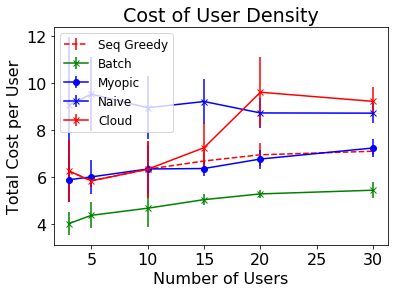

In [16]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = [3,5,10,15 ,20,30]

plt.errorbar(x_ax, total_costs_SG, total_costs_SG_var, color = 'r', linestyle = 'dashed', label = 'Seq Greedy')
plt.errorbar(x_ax, total_costs_Batch, total_costs_Batch_var,  color = 'green', marker = 'x', label = 'Batch')
plt.errorbar(x_ax, total_costs_Myopic, total_costs_Myopic_var, color = 'blue', marker = 'o', label = 'Myopic')
plt.errorbar(x_ax, total_costs_Naive, total_costs_Naive_var, color = 'blue', marker =  'x', label = 'Naive')
plt.errorbar(x_ax, total_costs_Cloud, total_costs_Cloud_var, color = 'red', marker ='x', label = 'Cloud')

# plt.xticks(x_ax)
# plt.xscale('log')
plt.legend(loc = 'upper left', prop={'size': 12})# plt.ylim(0,)


plt.title('Cost of User Density')
plt.xlabel('Number of Users')
plt.ylabel('Total Cost per User')

Text(0,0.5,'Latency Cost per User')

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


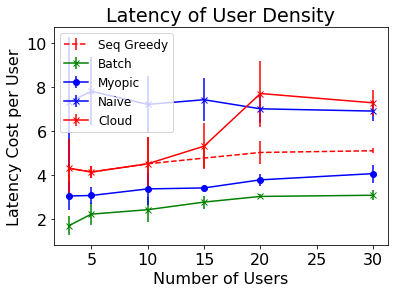

In [17]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = [3,5,10,15,20 ,30]

plt.errorbar(x_ax, latencies_SG, latencies_SG_var, color = 'r', linestyle = 'dashed', label = 'Seq Greedy')
plt.errorbar(x_ax, latencies_Batch, latencies_Batch_var,  color = 'green', marker = 'x', label = 'Batch')
plt.errorbar(x_ax, latencies_Myopic, latencies_Myopic_var, color = 'blue', marker = 'o', label = 'Myopic')
plt.errorbar(x_ax, latencies_Naive, latencies_Naive_var, color = 'blue', marker =  'x', label = 'Naive')
plt.errorbar(x_ax, latencies_Cloud, latencies_Cloud_var, color = 'red', marker ='x', label = 'Cloud')


# plt.xticks(x_ax)
# plt.xscale('log')
plt.legend(loc = 'upper left', prop={'size': 12})# plt.ylim(-0.2,)


plt.title('Latency of User Density')
plt.xlabel('Number of Users')
plt.ylabel('Latency Cost per User')

In [18]:
# Migration and user density
mig_SG = []
mig_Batch = []
mig_Myopic = []
mig_Cloud = []
mig_Naive = []

mig_SG_var = []
mig_Batch_var = []
mig_Myopic_var = []
mig_Cloud_var = []
mig_Naive_var = []

for i in range(len(num_users_list)):
    # open a file, where you stored the pickled data
    total_users = np.sum(num_users_list[i])
    name = "/sim_store/sim20/n2_mig_store_u"+ str(total_users) +".p"
    file = open(os.path.curdir + name, 'rb')

    # dump information to that file
    data = pickle.load(file)
    
    mig_SG += [np.divide(np.mean(data['SG']), np.sum(num_users_list[i]))]
    mig_Batch += [np.divide(np.mean(data['Batch']), np.sum(num_users_list[i]))]
    mig_Myopic += [np.divide(np.mean(data['Myopic']), np.sum(num_users_list[i]))]
    mig_Cloud += [np.divide(np.mean(data['Cloud']), np.sum(num_users_list[i]))]
    mig_Naive += [np.divide(np.mean(data['Naive']), np.sum(num_users_list[i]))]
    
    mig_SG_var += [np.divide(np.std(data['SG']), np.sum(num_users_list[i]))]
    mig_Batch_var += [np.divide(np.std(data['Batch']), np.sum(num_users_list[i]))]
    mig_Myopic_var += [np.divide(np.std(data['Myopic']), np.sum(num_users_list[i]))]
    mig_Cloud_var += [np.divide(np.std(data['Cloud']), np.sum(num_users_list[i]))]
    mig_Naive_var += [np.divide(np.std(data['Naive']), np.sum(num_users_list[i]))]

Text(0,0.5,'Migrations per User')

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


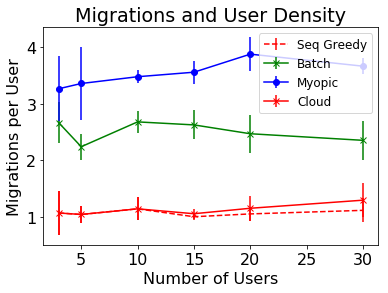

In [21]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = [3, 5,10,15,20 ,30]

plt.errorbar(x_ax, mig_SG, mig_SG_var, color = 'r', linestyle = 'dashed', label = 'Seq Greedy')
plt.errorbar(x_ax, mig_Batch, mig_Batch_var,  color = 'green', marker = 'x', label = 'Batch')
plt.errorbar(x_ax, mig_Myopic, mig_Myopic_var, color = 'blue', marker = 'o', label = 'Myopic')
plt.errorbar(x_ax, mig_Cloud, mig_Cloud_var, color = 'red', marker ='x', label = 'Cloud')


# plt.xticks(x_ax)
# plt.xscale('log')
plt.legend(loc = 'best', prop={'size': 12})# plt.ylim(-0.2,)
# plt.ylim(-0.2,)


plt.title('Migrations and User Density')
plt.xlabel('Number of Users')
plt.ylabel('Migrations per User')